# Phase 1 · LegalSeq2Seq · Encoder–decoder

## 1 · Setup

In [1]:
import os
import sys
import time
import subprocess
from pathlib import Path

SESSION_START = time.monotonic()
subprocess.run([sys.executable, '-m', 'pip', 'install', '-q',
                'tokenizers', 'huggingface_hub', 'ijson', 'cloudpickle',
                'rouge-score', 'sacrebleu', 'bert-score', 'transformers<5'], check=True)
os.environ['TOKENIZERS_PARALLELISM'] = 'false'
os.environ['OMP_NUM_THREADS'] = '2'
os.environ['HF_HUB_DISABLE_PROGRESS_BARS'] = '1'


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.0/44.0 kB 2.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 149.9/149.9 kB 8.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 100.8/100.8 kB 6.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.1/61.1 kB 3.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 112.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 74.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 26.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 129.6/129.6 kB 5.9 MB/s eta 0:00:00


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.26.0 requires huggingface-hub<2.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.40.0 requires huggingface-hub<2.0,>=1.23.0, but you have huggingface-hub 0.36.2 which is incompatible.


## 2 · Hugging Face token

In [2]:
hf_token = os.environ.get("HF_TOKEN")


## 3 · Configuration

In [3]:
import json

RUN_NAME = 'phase1_s03_legalseq2seq176m'
OUT = Path('/kaggle/working') / RUN_NAME
OUT.mkdir(parents=True, exist_ok=True)

CFG = {
    'output': str(OUT), 'repo': 'Exploration-Lab/CS-781-Capstone',
    'dataset_revision': None, 'seed': 42, 'tokenizer_path': '',
    'source_mix': {'high_courts': 0.45, 'supreme_court': 0.35, 'acts': 0.10, 'tribunals': 0.10},
    'corpus_tokens': 400000000, 'train_tokens': 700000000,
    'val_tokens_per_source': 250000, 'dev_examples_per_source': 16,
    'tokenizer_chars_per_source': 12000000, 'vocab_size': 32000,
    'dim': 768, 'heads': 12, 'encoder_layers': 8, 'decoder_layers': 10, 'ffn_dim': 2048,
    'encoder_tokens': 1536, 'decoder_tokens': 512, 'gradient_checkpointing': True,
    'micro_batch': 2, 'accumulation_steps': 8,
    'lr': 2.0e-4, 'min_lr': 2.0e-5, 'warmup_steps': 150,
    'weight_decay': 0.1, 'grad_clip': 1.0,
    'train_hours': 12.0, 'session_hours': 13.0, 'reserve_hours': 1.5, 'calibration_steps': 20,
    'log_every': 100, 'eval_every': 200, 'save_every': 200, 'eval_pairs_per_source': 64,
    'generation_batch_size': 4, 'max_generation_tokens': 512,
    'use_bertscore': True, 'bertscore_model': 'roberta-large',
    'decoding_candidates': [
        {'name': 'greedy', 'temperature': 0.0, 'top_p': 1.0, 'repetition_penalty': 1.08},
        {'name': 'sample070', 'temperature': 0.7, 'top_p': 0.92, 'repetition_penalty': 1.08},
        {'name': 'sample080_rep120', 'temperature': 0.8, 'top_p': 0.95, 'repetition_penalty': 1.2},
    ],
}
(OUT / 'config.json').write_text(json.dumps(CFG, indent=2))


1515

## 4 · LegalSeq2Seq model

In [4]:
import math
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.checkpoint import checkpoint


class RMSNorm(nn.Module):
    def __init__(self, dim):
        super().__init__()
        self.weight = nn.Parameter(torch.ones(dim))

    def forward(self, x):
        z = x.float()
        z = z * torch.rsqrt(z.square().mean(-1, keepdim=True) + 1e-5)
        return z.to(x.dtype) * self.weight


class SelfAttention(nn.Module):
    def __init__(self, cfg, causal):
        super().__init__()
        self.heads = cfg['heads']
        self.head_dim = cfg['dim'] // self.heads
        self.causal = causal
        self.qkv = nn.Linear(cfg['dim'], 3 * cfg['dim'], bias=False)
        self.out = nn.Linear(cfg['dim'], cfg['dim'], bias=False)
        inv = 10000 ** (-torch.arange(0, self.head_dim, 2).float() / self.head_dim)
        self.register_buffer('inv_freq', inv, persistent=False)

    def rope(self, x, positions):
        phase = positions.float().unsqueeze(-1) * self.inv_freq.float()
        cos, sin = phase.cos()[None, None].to(x.dtype), phase.sin()[None, None].to(x.dtype)
        even, odd = x[..., ::2], x[..., 1::2]
        return torch.stack((even * cos - odd * sin, even * sin + odd * cos), -1).flatten(-2)

    def forward(self, x, mask=None, past=None, use_cache=False):
        b, t, d = x.shape
        q, k, v = self.qkv(x).view(b, t, 3, self.heads, self.head_dim).unbind(2)
        q, k, v = (z.transpose(1, 2) for z in (q, k, v))
        old = 0 if past is None else past[0].size(2)
        positions = torch.arange(old, old + t, device=x.device)
        q, k = self.rope(q, positions), self.rope(k, positions)
        if past is not None:
            k, v = torch.cat((past[0], k), 2), torch.cat((past[1], v), 2)
        allowed = None if mask is None else mask[:, None, None, :]
        fast_causal = self.causal and past is None and mask is None
        if self.causal and not fast_causal:
            causal_mask = torch.arange(k.size(2), device=x.device)[None, :] <= positions[:, None]
            allowed = causal_mask[None, None] if allowed is None else allowed & causal_mask[None, None]
        y = F.scaled_dot_product_attention(q, k, v, attn_mask=allowed,
                                          is_causal=fast_causal, dropout_p=0.0)
        y = self.out(y.transpose(1, 2).contiguous().view(b, t, d))
        return y, (k, v) if use_cache else None


class CrossAttention(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.heads, self.head_dim = cfg['heads'], cfg['dim'] // cfg['heads']
        self.q = nn.Linear(cfg['dim'], cfg['dim'], bias=False)
        self.kv = nn.Linear(cfg['dim'], 2 * cfg['dim'], bias=False)
        self.out = nn.Linear(cfg['dim'], cfg['dim'], bias=False)

    def project_memory(self, memory):
        b, s, _ = memory.shape
        k, v = self.kv(memory).view(b, s, 2, self.heads, self.head_dim).unbind(2)
        return k.transpose(1, 2), v.transpose(1, 2)

    def forward(self, x, memory, mask, cached=None):
        b, t, d = x.shape
        q = self.q(x).view(b, t, self.heads, self.head_dim).transpose(1, 2)
        k, v = self.project_memory(memory) if cached is None else cached
        y = F.scaled_dot_product_attention(q, k, v, attn_mask=mask[:, None, None, :], dropout_p=0.0)
        return self.out(y.transpose(1, 2).contiguous().view(b, t, d))


class FeedForward(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        d, f = cfg['dim'], cfg['ffn_dim']
        self.gate = nn.Linear(d, f, bias=False)
        self.up = nn.Linear(d, f, bias=False)
        self.down = nn.Linear(f, d, bias=False)

    def forward(self, x):
        return self.down(F.silu(self.gate(x)) * self.up(x))


class EncoderBlock(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.norm1, self.norm2 = RMSNorm(cfg['dim']), RMSNorm(cfg['dim'])
        self.attn = SelfAttention(cfg, causal=False)
        self.ffn = FeedForward(cfg)

    def forward(self, x, mask):
        x = x + self.attn(self.norm1(x), mask)[0]
        return x + self.ffn(self.norm2(x))


class DecoderBlock(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.norm1, self.norm2, self.norm3 = (RMSNorm(cfg['dim']) for _ in range(3))
        self.attn = SelfAttention(cfg, causal=True)
        self.cross = CrossAttention(cfg)
        self.ffn = FeedForward(cfg)

    def forward(self, x, memory, source_mask, target_mask=None, past=None, cross_kv=None, use_cache=False):
        a, cache = self.attn(self.norm1(x), target_mask, past, use_cache)
        x = x + a
        x = x + self.cross(self.norm2(x), memory, source_mask, cross_kv)
        return x + self.ffn(self.norm3(x)), cache


class LegalSeq2Seq(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.cfg = dict(cfg)
        self.embed = nn.Embedding(cfg['vocab_size'], cfg['dim'])
        self.encoder = nn.ModuleList([EncoderBlock(cfg) for _ in range(cfg['encoder_layers'])])
        self.decoder = nn.ModuleList([DecoderBlock(cfg) for _ in range(cfg['decoder_layers'])])
        self.encoder_norm, self.decoder_norm = RMSNorm(cfg['dim']), RMSNorm(cfg['dim'])
        self.apply(self._init)
        for block in self.encoder:
            for weight in (block.attn.out.weight, block.ffn.down.weight):
                nn.init.normal_(weight, std=0.02 / math.sqrt(2 * len(self.encoder)))
        for block in self.decoder:
            for weight in (block.attn.out.weight, block.cross.out.weight, block.ffn.down.weight):
                nn.init.normal_(weight, std=0.02 / math.sqrt(3 * len(self.decoder)))

    @staticmethod
    def _init(module):
        if isinstance(module, (nn.Linear, nn.Embedding)):
            nn.init.normal_(module.weight, std=0.02)

    def encode(self, source, source_mask):
        x = self.embed(source)
        for block in self.encoder:
            if self.training and self.cfg['gradient_checkpointing']:
                x = checkpoint(block, x, source_mask, use_reentrant=False)
            else:
                x = block(x, source_mask)
        return self.encoder_norm(x)

    def decode(self, target, memory, source_mask, target_mask=None, past=None, cross_kv=None, use_cache=False):
        x, caches = self.embed(target), []
        for i, block in enumerate(self.decoder):
            if self.training and self.cfg['gradient_checkpointing']:
                def layer(z, mem, module=block):
                    return module(z, mem, source_mask, target_mask)[0]
                x = checkpoint(layer, x, memory, use_reentrant=False)
            else:
                x, cache = block(x, memory, source_mask, target_mask,
                                 None if past is None else past[i],
                                 None if cross_kv is None else cross_kv[i], use_cache)
                caches.append(cache)
        return self.decoder_norm(x), caches

    def forward(self, source, target, labels=None):
        source_mask = source.ne(self.cfg['pad_id'])
        memory = self.encode(source, source_mask)
        x, _ = self.decode(target, memory, source_mask, target.ne(self.cfg['pad_id']))
        if labels is None:
            return F.linear(x, self.embed.weight)
        h, y = x.flatten(0, 1), labels.flatten()
        total = h.new_zeros((), dtype=torch.float32)
        for start in range(0, len(y), 256):
            def part(z, truth):
                return F.cross_entropy(F.linear(z, self.embed.weight).float(), truth,
                                       ignore_index=-100, reduction='sum')
            if self.training:
                total = total + checkpoint(part, h[start:start+256], y[start:start+256], use_reentrant=False)
            else:
                total = total + part(h[start:start+256], y[start:start+256])
        return total


## 5 · Corpus and BPE

In [5]:
import hashlib
import itertools
import json
import os
import random
from pathlib import Path
import numpy as np
import ijson
from huggingface_hub import HfApi, HfFileSystem
from tokenizers import Tokenizer, models, pre_tokenizers, decoders, trainers


def fingerprint(text):
    return hashlib.blake2b(' '.join(text.split()).encode(), digest_size=16).hexdigest()


def is_validation(digest):
    return int(digest[:8], 16) % 100 == 0


def records(stream):
    first = stream.read(4096).lstrip()[:1]
    stream.seek(0)
    rows = ijson.items(stream, 'item') if first == b'[' else (v for _, v in ijson.kvitems(stream, ''))
    for row in rows:
        text = row if isinstance(row, str) else row['text']
        if text.strip():
            yield text


def shuffled(iterator, seed, size=256):
    rng = random.Random(seed)
    buffer = list(itertools.islice(iterator, size))
    for item in iterator:
        j = rng.randrange(len(buffer))
        yield buffer[j]
        buffer[j] = item
    rng.shuffle(buffer)
    yield from buffer


def encode_pair(tokenizer, prompt, continuation, cfg):
    source = tokenizer.encode(prompt, add_special_tokens=False).ids[-cfg['encoder_tokens']:]
    target = tokenizer.encode(continuation, add_special_tokens=False).ids + [tokenizer.token_to_id('<eos>')]
    return source, target[:cfg['decoder_tokens']]


def prepare_data(cfg):
    out, data = Path(cfg['output']), Path(cfg['output']) / 'data'
    data.mkdir(parents=True, exist_ok=True)
    if (data / 'manifest.json').exists():
        return json.loads((data / 'manifest.json').read_text())
    api = HfApi(token=os.environ['HF_TOKEN'])
    revision = cfg['dataset_revision'] or api.dataset_info(cfg['repo']).sha
    names = api.list_repo_files(cfg['repo'], repo_type='dataset', revision=revision)
    sources = {s: next(p for p in names if p.startswith('Phase_1_Pretraining/Train/')
                      and p.endswith('/train_' + s + '.json')) for s in cfg['source_mix']}
    test_file = next(p for p in names if p.startswith('Phase_1_Pretraining/Test/') and p.endswith('.json'))
    fs = HfFileSystem(token=os.environ['HF_TOKEN'])

    def stream(source):
        with fs.open(f"datasets/{cfg['repo']}@{revision}/{sources[source]}", 'rb', block_size=8*1024*1024) as f:
            yield from records(f)

    if cfg['tokenizer_path']:
        tokenizer = Tokenizer.from_file(cfg['tokenizer_path'])
    else:
        tokenizer = Tokenizer(models.BPE(unk_token='<unk>'))
        tokenizer.pre_tokenizer = pre_tokenizers.ByteLevel(add_prefix_space=False)
        tokenizer.decoder = decoders.ByteLevel()
        def samples():
            seen = set()
            for si, source in enumerate(sources):
                used = 0
                for text in shuffled(stream(source), cfg['seed'] + si):
                    h = fingerprint(text)
                    if is_validation(h) or h in seen:
                        continue
                    seen.add(h)
                    sample = text[:min(32768, cfg['tokenizer_chars_per_source'] - used)]
                    yield sample
                    used += len(sample)
                    if used >= cfg['tokenizer_chars_per_source']:
                        break
        trainer = trainers.BpeTrainer(vocab_size=cfg['vocab_size'], min_frequency=2,
                      special_tokens=['<pad>', '<bos>', '<eos>', '<unk>'],
                      initial_alphabet=pre_tokenizers.ByteLevel.alphabet(), show_progress=False)
        tokenizer.train_from_iterator(samples(), trainer=trainer)
    tokenizer.save(str(out / 'tokenizer.json'))
    seen, dev, stats = set(), [], {}
    for si, source in enumerate(sources):
        budgets = {'train': int(cfg['corpus_tokens'] * cfg['source_mix'][source]),
                   'val': cfg['val_tokens_per_source']}
        counts, indexes = {'train': 0, 'val': 0}, {'train': [], 'val': []}
        truncated = 0
        ndev = 0
        files = {split: (data / f'{source}.{split}.bin.tmp').open('wb') for split in budgets}
        for text in shuffled(stream(source), cfg['seed'] + si):
            digest = fingerprint(text)
            split = 'val' if is_validation(digest) else 'train'
            if digest in seen or counts[split] >= budgets[split]:
                continue
            seen.add(digest)
            words = text.split()
            if len(words) < 640:
                continue
            if split == 'val' and ndev < cfg['dev_examples_per_source']:
                start = int(digest[8:16], 16) % (len(words) - 639)
                dev.append({'id': source + '_' + digest, 'source': source,
                            'prompt': ' '.join(words[start:start+512]),
                            'reference': ' '.join(words[start+512:start+640])})
                ndev += 1
            start = int(digest[16:24], 16) % min(640, len(words) - 639)
            for pos in range(start, len(words) - 639, 640):
                prompt = ' '.join(words[pos:pos+512])
                continuation = ' '.join(words[pos+512:pos+640])
                x, y = encode_pair(tokenizer, prompt, continuation, cfg)
                truncated += int(y[-1] != tokenizer.token_to_id('<eos>'))
                indexes[split].append((counts[split], len(x), len(y)))
                np.asarray(x + y, dtype=np.uint16).tofile(files[split])
                counts[split] += len(x) + len(y)
                if counts[split] >= budgets[split]:
                    break
            if all(counts[s] >= budgets[s] for s in budgets):
                break
        for f in files.values():
            f.close()
        for split in budgets:
            os.replace(data / f'{source}.{split}.bin.tmp', data / f'{source}.{split}.bin')
            np.save(data / f'{source}.{split}.index.npy', np.asarray(indexes[split], dtype=np.int64).reshape(-1, 3))
        stats[source] = {'tokens': counts, 'pairs': {s: len(v) for s, v in indexes.items()},
                         'clipped_targets': truncated, 'dev_examples': ndev}
        print(f"{source}: {len(indexes['train']):,} training pairs, {counts['train']:,} tokens", flush=True)
    manifest = {'revision': revision, 'test_file': test_file, 'stats': stats,
                'vocab_size': tokenizer.get_vocab_size(),
                'special_ids': {s: tokenizer.token_to_id(s) for s in ['<pad>', '<bos>', '<eos>', '<unk>']},
                'tokenizer_sha256': hashlib.sha256((out / 'tokenizer.json').read_bytes()).hexdigest(),
                'encoder_tokens': cfg['encoder_tokens'], 'decoder_tokens': cfg['decoder_tokens']}
    (data / 'dev.json').write_text(json.dumps(dev, ensure_ascii=False))
    (data / 'manifest.json').write_text(json.dumps(manifest, indent=2))
    return manifest


class Pairs:
    def __init__(self, cfg, split):
        self.cfg = cfg
        self.names = list(cfg['source_mix'])
        data = Path(cfg['output']) / 'data'
        self.arrays = [np.memmap(data / f'{s}.{split}.bin', dtype=np.uint16, mode='r') for s in self.names]
        self.indexes = [np.load(data / f'{s}.{split}.index.npy', mmap_mode='r') for s in self.names]
        self.lengths = [len(a) for a in self.indexes]
        self.ends = np.cumsum(self.lengths)
        self.size = int(self.ends[-1])
        self.epoch, self.order = None, None

    def batch(self, indexes, device, permute=True):
        rows = []
        for index in indexes:
            epoch, offset = divmod(int(index), self.size)
            if permute:
                if epoch != self.epoch:
                    self.order = np.random.default_rng(self.cfg['seed'] + epoch).permutation(self.size)
                    self.epoch = epoch
                offset = int(self.order[offset])
            s = int(np.searchsorted(self.ends, offset, side='right'))
            local = offset - (int(self.ends[s-1]) if s else 0)
            start, nx, ny = map(int, self.indexes[s][local])
            x = np.asarray(self.arrays[s][start:start+nx], dtype=np.int64)
            y = np.asarray(self.arrays[s][start+nx:start+nx+ny], dtype=np.int64)
            rows.append((x, y))
        source_len = math.ceil(max(len(x) for x, _ in rows) / 8) * 8
        target_len = math.ceil(max(len(y) for _, y in rows) / 8) * 8
        source = torch.full((len(rows), source_len), self.cfg['pad_id'], dtype=torch.long)
        target = torch.full((len(rows), target_len), self.cfg['pad_id'], dtype=torch.long)
        labels = torch.full_like(target, -100)
        for i, (x, y) in enumerate(rows):
            source[i, :len(x)] = torch.from_numpy(x.copy())
            labels[i, :len(y)] = torch.from_numpy(y.copy())
            target[i, 0] = self.cfg['bos_id']
            target[i, 1:len(y)] = torch.from_numpy(y[:-1].copy())
        return tuple(t.to(device) for t in (source, target, labels))


In [6]:
manifest = prepare_data(CFG)
CFG.update(vocab_size=manifest['vocab_size'], dataset_revision=manifest['revision'],
           pad_id=manifest['special_ids']['<pad>'], bos_id=manifest['special_ids']['<bos>'],
           eos_id=manifest['special_ids']['<eos>'], unk_id=manifest['special_ids']['<unk>'])
(OUT / 'config.json').write_text(json.dumps(CFG, indent=2))
print(f"BPE vocabulary: {CFG['vocab_size']:,}")


BPE vocabulary: 32,000


## 6 · Training

In [7]:
import contextlib
import time
from datetime import timedelta
import torch.distributed as dist
from torch.nn.parallel import DistributedDataParallel as DDP


def atomic_save(payload, path):
    tmp = str(path) + '.tmp'
    torch.save(payload, tmp)
    os.replace(tmp, path)


@torch.no_grad()
def evaluate(model, data, cfg, rank, world, device):
    model.eval()
    totals = torch.zeros(len(data.names), 2, dtype=torch.float64, device=device)
    for s, count in enumerate(data.lengths):
        chosen = np.random.default_rng(cfg['seed'] + s + 999).choice(
            count, min(count, cfg['eval_pairs_per_source']), replace=False)
        base = int(data.ends[s-1]) if s else 0
        chosen = (chosen + base)[rank::world]
        for start in range(0, len(chosen), cfg['micro_batch']):
            x, y, labels = data.batch(chosen[start:start+cfg['micro_batch']], device, permute=False)
            with torch.autocast('cuda', dtype=torch.float16):
                loss = model(x, y, labels)
            totals[s, 0] += loss.double()
            totals[s, 1] += labels.ne(-100).sum()
    dist.all_reduce(totals)
    losses = {s: float(totals[i, 0] / totals[i, 1]) for i, s in enumerate(data.names)}
    model.train()
    return sum(cfg['source_mix'][s] * losses[s] for s in data.names), losses


def train_worker(rank, world, cfg):
    torch.set_num_threads(2)
    torch.cuda.set_device(rank)
    device = torch.device('cuda', rank)
    dist.init_process_group('nccl', rank=rank, world_size=world,
                            device_id=device, timeout=timedelta(minutes=30))
    torch.manual_seed(cfg['seed'])
    torch.cuda.manual_seed(cfg['seed'])
    out = Path(cfg['output'])
    train, val = Pairs(cfg, 'train'), Pairs(cfg, 'val')
    model = LegalSeq2Seq(cfg).to(device)
    params = list(model.parameters())
    groups = [{'params': [p for p in params if p.ndim >= 2], 'weight_decay': cfg['weight_decay']},
              {'params': [p for p in params if p.ndim < 2], 'weight_decay': 0.0}]
    optimizer = torch.optim.AdamW(groups, lr=cfg['lr'], betas=(0.9, 0.95), eps=1e-8, fused=True)
    scaler = torch.amp.GradScaler('cuda', init_scale=256)
    global_batch = world * cfg['micro_batch'] * cfg['accumulation_steps']
    mean_tokens = sum(int(a[:, 1:].sum()) for a in train.indexes) / train.size
    max_steps = math.ceil(cfg['train_tokens'] / (global_batch * mean_tokens))
    step, consumed, target_tokens, cursor, best = 0, 0, 0, 0, float('inf')
    target_steps, calibrated = max_steps, False
    if (out / 'last.pt').exists():
        state = torch.load(out / 'last.pt', map_location='cpu', weights_only=False)
        model.load_state_dict(state['model'])
        optimizer.load_state_dict(state['optimizer'])
        scaler.load_state_dict(state['scaler'])
        step, consumed, target_tokens = state['step'], state['tokens'], state['target_tokens']
        cursor, best = state['cursor'], state['best_loss']
        target_steps, calibrated = state['target_steps'], True
        torch.set_rng_state(state['rng'][rank]['cpu'])
        torch.cuda.set_rng_state(state['rng'][rank]['cuda'], device)
        if cfg['train_tokens'] > state['config']['train_tokens']:
            target_steps, calibrated = max_steps, False
        del state
    ddp = DDP(model, device_ids=[rank], broadcast_buffers=False, gradient_as_bucket_view=True)
    start_time, start_step = time.monotonic(), step
    max_seconds = cfg['train_hours'] * 3600
    if rank == 0:
        count = sum(p.numel() for p in model.parameters())
        print(f'Training: {count:,} parameters | batch: {global_batch} pairs | resume step: {step:,}', flush=True)

    def save(improved=False):
        rng = {'cpu': torch.get_rng_state(), 'cuda': torch.cuda.get_rng_state(device)}
        rngs = [None] * world
        dist.all_gather_object(rngs, rng)
        if rank == 0:
            payload = {'model': model.state_dict(), 'optimizer': optimizer.state_dict(),
                       'scaler': scaler.state_dict(), 'config': cfg, 'step': step,
                       'tokens': consumed, 'target_tokens': target_tokens, 'cursor': cursor,
                       'best_loss': best, 'target_steps': target_steps, 'rng': rngs}
            atomic_save(payload, out / 'last.pt')
            if improved:
                atomic_save({'model': model.state_dict(), 'config': cfg, 'step': step,
                             'val_loss': best}, out / 'best.pt')
        dist.barrier(device_ids=[rank])

    overflows = 0
    while step < target_steps and consumed < cfg['train_tokens']:
        if step < cfg['warmup_steps']:
            lr = cfg['lr'] * (step + 1) / cfg['warmup_steps']
        else:
            progress = min(1.0, (step-cfg['warmup_steps']) / max(1, target_steps-cfg['warmup_steps']-1))
            lr = cfg['min_lr'] + 0.5*(cfg['lr']-cfg['min_lr'])*(1+math.cos(math.pi*progress))
        for group in optimizer.param_groups:
            group['lr'] = lr
        batches = []
        for micro in range(cfg['accumulation_steps']):
            offset = cursor + (micro * world + rank) * cfg['micro_batch']
            batches.append(train.batch(range(offset, offset + cfg['micro_batch']), torch.device('cpu')))
        counts = torch.tensor([sum(int(y.ne(-100).sum()) for _, _, y in batches),
                               sum(int(x.ne(cfg['pad_id']).sum()) for x, _, _ in batches)],
                              device=device, dtype=torch.long)
        dist.all_reduce(counts)
        optimizer.zero_grad(set_to_none=True)
        total_loss = torch.zeros((), device=device)
        for micro, batch in enumerate(batches):
            x, y, labels = (t.to(device) for t in batch)
            sync = contextlib.nullcontext() if micro == len(batches)-1 else ddp.no_sync()
            with sync:
                with torch.autocast('cuda', dtype=torch.float16):
                    loss = ddp(x, y, labels)
                total_loss += loss.detach()
                scaler.scale(loss * world / counts[0]).backward()
        scaler.unscale_(optimizer)
        grad_norm = torch.nn.utils.clip_grad_norm_(model.parameters(), cfg['grad_clip'])
        old_scale = scaler.get_scale()
        scaler.step(optimizer)
        scaler.update()
        if scaler.get_scale() < old_scale:
            overflows += 1
            if overflows >= 25:
                raise FloatingPointError('25 consecutive FP16 overflows')
            continue
        overflows = 0
        step += 1
        cursor += global_batch
        consumed += int(counts.sum())
        target_tokens += int(counts[0])
        elapsed = time.monotonic() - start_time
        if not calibrated and step-start_step >= cfg['calibration_steps']:
            timing = torch.tensor(elapsed, device=device)
            dist.all_reduce(timing, op=dist.ReduceOp.MAX)
            seconds_per_step = float(timing) / (step-start_step)
            remaining = max(0, max_seconds-float(timing)-300)
            target_steps = min(max_steps, step + max(1, int(remaining * 0.8 / seconds_per_step)))
            calibrated = True
            if rank == 0:
                print(f'Runtime target: {target_steps:,} steps', flush=True)
        stop = torch.tensor(int(elapsed >= max_seconds-180 or consumed >= cfg['train_tokens']
                                or step >= target_steps), device=device)
        dist.all_reduce(stop, op=dist.ReduceOp.MAX)
        stopping = bool(stop)
        log = None
        if step % cfg['log_every'] == 0 or stopping:
            dist.all_reduce(total_loss)
            log = {'step': step, 'train_loss': float(total_loss/counts[0]), 'lr': lr,
                   'tokens': consumed, 'target_tokens': target_tokens, 'hours': elapsed/3600}
        if step % cfg['eval_every'] == 0 or stopping:
            val_loss, source_losses = evaluate(model, val, cfg, rank, world, device)
            if not math.isfinite(val_loss):
                raise FloatingPointError('Non-finite validation loss')
            improved = val_loss < best
            best = min(best, val_loss)
            log = dict(log or {'step': step}, val_loss=val_loss,
                       perplexity=math.exp(min(val_loss, 80)), source_losses=source_losses)
            save(improved)
        elif step % cfg['save_every'] == 0:
            save()
        if rank == 0 and log:
            with (out / 'training.jsonl').open('a') as f:
                f.write(json.dumps(log) + '\n')
            fields = ['step', 'train_loss', 'val_loss', 'perplexity']
            print(' | '.join(f'{k}: {log[k]:.4f}' if k != 'step' else f'step: {step}'
                             for k in fields if k in log), flush=True)
        if stopping:
            break
    if rank == 0:
        summary = {'parameters': sum(p.numel() for p in model.parameters()), 'steps': step,
                   'processed_source_and_target_tokens': consumed, 'supervised_target_tokens': target_tokens,
                   'best_val_loss': best, 'target_steps': target_steps,
                   'hours_this_session': (time.monotonic()-start_time)/3600}
        (out / 'training_summary.json').write_text(json.dumps(summary, indent=2))
    dist.destroy_process_group()


## 7 · Two-GPU launcher

In [8]:
import cloudpickle
import socket
import subprocess
import sys


def launch(worker, *args):
    payload = OUT / 'worker.pkl'
    with payload.open('wb') as f:
        cloudpickle.dump((worker, CFG, args), f)
    with socket.socket() as sock:
        sock.bind(('127.0.0.1', 0))
        port = sock.getsockname()[1]
    program = (
        "import cloudpickle,os; "
        "f=open('worker.pkl','rb'); fn,cfg,args=cloudpickle.load(f); f.close(); "
        "fn(int(os.environ['RANK']),int(os.environ['WORLD_SIZE']),cfg,*args)"
    )
    processes = []
    for rank in range(2):
        env = dict(os.environ, MASTER_ADDR='127.0.0.1', MASTER_PORT=str(port),
                   RANK=str(rank), LOCAL_RANK=str(rank), WORLD_SIZE='2', PYTHONUNBUFFERED='1')
        processes.append(subprocess.Popen([sys.executable, '-c', program], cwd=OUT, env=env))
    for process in processes:
        process.wait()
        if process.returncode:
            raise subprocess.CalledProcessError(process.returncode, process.args)
    payload.unlink(missing_ok=True)


In [9]:
elapsed = (time.monotonic() - SESSION_START) / 3600
run_cfg = dict(CFG)
run_cfg['train_hours'] = min(CFG['train_hours'], CFG['session_hours'] - elapsed - CFG['reserve_hours'])
CFG = run_cfg
(OUT / 'config.json').write_text(json.dumps(CFG, indent=2))
launch(train_worker)
summary = json.loads((OUT / 'training_summary.json').read_text())
print(f"Completed {summary['steps']:,} steps | best validation loss: {summary['best_val_loss']:.4f}")


Training: 175,607,808 parameters | batch: 32 pairs | resume step: 21,096
Completed 21,096 steps | best validation loss: 2.4789


In [10]:
elapsed = (time.monotonic() - SESSION_START) / 3600
run_cfg = dict(CFG)
run_cfg['train_hours'] = min(CFG['train_hours'], CFG['session_hours'] - elapsed - CFG['reserve_hours'])
CFG = run_cfg
(OUT / 'config.json').write_text(json.dumps(CFG, indent=2))
launch(train_worker)
summary = json.loads((OUT / 'training_summary.json').read_text())
print(f"Completed {summary['steps']:,} steps | best validation loss: {summary['best_val_loss']:.4f}")


Training: 175,607,808 parameters | batch: 32 pairs | resume step: 21,096
Completed 21,096 steps | best validation loss: 2.4789


## 8 · Learning curves

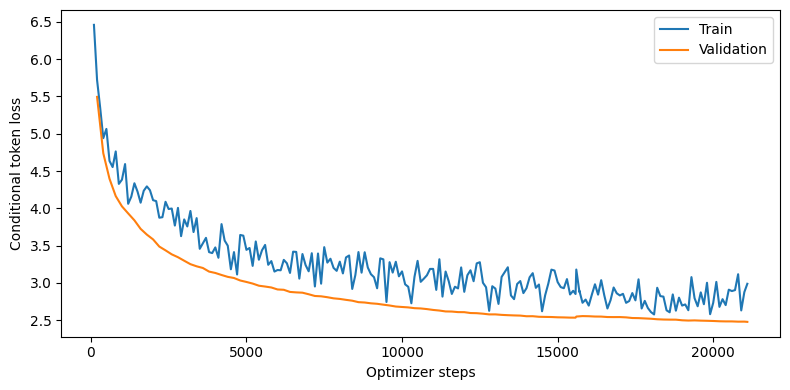

In [11]:
import matplotlib.pyplot as plt

logs = [json.loads(line) for line in (OUT / 'training.jsonl').read_text().splitlines()]
fig, ax = plt.subplots(figsize=(8, 4))
for key, label in [('train_loss', 'Train'), ('val_loss', 'Validation')]:
    points = [r for r in logs if key in r]
    ax.plot([r['step'] for r in points], [r[key] for r in points], label=label)
ax.set(xlabel='Optimizer steps', ylabel='Conditional token loss')
ax.legend()
fig.tight_layout()
fig.savefig(OUT / 'learning_curves.png', dpi=150)
plt.show()


## 9 · Generation

In [12]:
@torch.inference_mode()
def generate(model, tokenizer, prompts, cfg, decoding, device):
    pad, bos, eos = cfg['pad_id'], cfg['bos_id'], cfg['eos_id']
    encoded = [tokenizer.encode(p, add_special_tokens=False).ids[-cfg['encoder_tokens']:] or [bos]
               for p in prompts]
    source = torch.full((len(prompts), max(map(len, encoded))), pad, dtype=torch.long, device=device)
    for i, ids in enumerate(encoded):
        source[i, :len(ids)] = torch.tensor(ids, device=device)
    source_mask = source.ne(pad)
    with torch.autocast('cuda', dtype=torch.float16, enabled=device.type == 'cuda'):
        memory = model.encode(source, source_mask)
        cross_kv = [block.cross.project_memory(memory) for block in model.decoder]
    current = torch.full((len(prompts), 1), bos, dtype=torch.long, device=device)
    generated, done, cache = [[] for _ in prompts], [False] * len(prompts), None
    penalty = decoding['repetition_penalty']
    for step in range(cfg['max_generation_tokens']):
        with torch.autocast('cuda', dtype=torch.float16, enabled=device.type == 'cuda'):
            hidden, cache = model.decode(current, memory, source_mask, past=cache,
                                         cross_kv=cross_kv, use_cache=True)
            scores = F.linear(hidden[:, -1], model.embed.weight).float()
        scores[:, [pad, bos, cfg['unk_id']]] = -float('inf')
        for i, ids in enumerate(generated):
            if ids and not done[i]:
                seen = torch.tensor(list(set(ids[-256:])), device=device)
                values = scores[i, seen]
                scores[i, seen] = torch.where(values < 0, values * penalty, values / penalty)
        if decoding['temperature'] == 0:
            next_ids = scores.argmax(-1)
        else:
            values, indexes = (scores / decoding['temperature']).sort(descending=True)
            probs = values.softmax(-1)
            values.masked_fill_(probs.cumsum(-1) - probs > decoding['top_p'], -float('inf'))
            next_ids = indexes.gather(-1, torch.multinomial(values.softmax(-1), 1)).squeeze(-1)
        for i, token in enumerate(next_ids.tolist()):
            if not done[i]:
                if token == eos:
                    done[i] = True
                else:
                    generated[i].append(token)
        if (step+1) % 8 == 0:
            for i, text in enumerate(tokenizer.decode_batch(generated, skip_special_tokens=True)):
                done[i] = done[i] or len(text.split()) >= 129
        if all(done):
            break
        current = next_ids[:, None]
    texts = tokenizer.decode_batch(generated, skip_special_tokens=True)
    return [' '.join(text.split()[:128]) for text in texts]


def infer_worker(rank, world, cfg, mode):
    torch.set_num_threads(2)
    torch.cuda.set_device(rank)
    device = torch.device('cuda', rank)
    out = Path(cfg['output'])
    state = torch.load(out / 'best.pt', map_location='cpu', weights_only=True)
    model_cfg = state['config']
    model = LegalSeq2Seq(model_cfg)
    model.load_state_dict(state['model'])
    model.to(device).eval()
    del state
    tokenizer = Tokenizer.from_file(str(out / 'tokenizer.json'))
    if mode == 'dev':
        examples = json.loads((out / 'data' / 'dev.json').read_text())
        candidates = cfg['decoding_candidates']
    else:
        test = json.loads((out / 'test.json').read_text())
        examples = [{'id': k, 'prompt': v['text']} for k, v in test.items()]
        candidates = [json.loads((out / 'selected_decoding.json').read_text())['decoding']]
    examples = sorted(examples[rank::world], key=lambda row: len(row['prompt']))
    for candidate in candidates:
        torch.manual_seed(cfg['seed'] + rank)
        torch.cuda.manual_seed(cfg['seed'] + rank)
        predictions = {}
        for start in range(0, len(examples), cfg['generation_batch_size']):
            rows = examples[start:start+cfg['generation_batch_size']]
            texts = generate(model, tokenizer, [r['prompt'] for r in rows], cfg, candidate, device)
            predictions.update({r['id']: {'text': text} for r, text in zip(rows, texts)})
        (out / f"{mode}_{candidate['name']}_rank{rank}.json").write_text(json.dumps(predictions, ensure_ascii=False))


## 10 · Dev decoding comparison

In [13]:
launch(infer_worker, 'dev')

import gc
import sacrebleu
from rouge_score import rouge_scorer

scorer = rouge_scorer.RougeScorer(['rougeL'], use_stemmer=True)
dev = json.loads((OUT / 'data' / 'dev.json').read_text())
truths = [r['reference'] for r in dev]
if CFG['use_bertscore']:
    from bert_score import BERTScorer
    bert = BERTScorer(model_type=CFG['bertscore_model'], lang='en', device='cuda:0',
                      batch_size=8, rescale_with_baseline=False)
metrics = []
for candidate in CFG['decoding_candidates']:
    merged = {}
    for rank in range(2):
        merged.update(json.loads((OUT / f"dev_{candidate['name']}_rank{rank}.json").read_text()))
    hypotheses = [merged[r['id']]['text'] for r in dev]
    rouge = [scorer.score(ref, hyp)['rougeL'].fmeasure for ref, hyp in zip(truths, hypotheses)]
    row = {'decoding': candidate, 'rougeL': sum(rouge)/len(rouge),
           'bleu': sacrebleu.corpus_bleu(hypotheses, [truths]).score,
           'mean_words': sum(len(x.split()) for x in hypotheses)/len(hypotheses),
           'short_outputs': sum(len(x.split()) < 128 for x in hypotheses)}
    if CFG['use_bertscore']:
        _, _, f1 = bert.score(hypotheses, truths)
        row['bertscore_f1'] = float(f1.mean())
        row['bertscore_model'] = CFG['bertscore_model']
    metrics.append(row)
    (OUT / f"dev_prediction_{candidate['name']}.json").write_text(json.dumps(merged, ensure_ascii=False))
    print(candidate['name'], '|', ' | '.join(f'{k}: {row[k]:.4f}'
          for k in ['bertscore_f1', 'rougeL', 'bleu'] if k in row))
selected = max(metrics, key=lambda r: (r.get('bertscore_f1', r['rougeL']), r['rougeL'], r['bleu']))
(OUT / 'selected_decoding.json').write_text(json.dumps(selected, indent=2))
(OUT / 'decoding_metrics.json').write_text(json.dumps(metrics, indent=2))
(OUT / 'dev_reference.json').write_text(json.dumps({r['id']: {'text': r['reference']} for r in dev}))
if CFG['use_bertscore']:
    del bert
    gc.collect()
    torch.cuda.empty_cache()
print('Selected:', selected['decoding']['name'])


Some weights of RobertaModel were not initialized from the model checkpoint at roberta-large and are newly initialized: ['pooler.dense.bias', 'pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


greedy | bertscore_f1: 0.8211 | rougeL: 0.2548 | bleu: 11.6471
sample070 | bertscore_f1: 0.8355 | rougeL: 0.2395 | bleu: 11.0952
sample080_rep120 | bertscore_f1: 0.8300 | rougeL: 0.2118 | bleu: 7.8270
Selected: sample070


## 11 · Test and submission

In [14]:
from huggingface_hub import hf_hub_download
import zipfile

path = hf_hub_download(repo_id=CFG['repo'], repo_type='dataset', filename=manifest['test_file'],
                       revision=manifest['revision'], token=os.environ['HF_TOKEN'])
test = json.loads(Path(path).read_text())
(OUT / 'test.json').write_text(json.dumps(test, ensure_ascii=False))
launch(infer_worker, 'test')

predictions = {}
name = selected['decoding']['name']
for rank in range(2):
    predictions.update(json.loads((OUT / f'test_{name}_rank{rank}.json').read_text()))
predictions = {key: predictions[key] for key in test}
prediction_path = OUT / 'prediction.json'
prediction_path.write_text(json.dumps(predictions, ensure_ascii=False, indent=2))
with zipfile.ZipFile(OUT / 'submission.zip', 'w', zipfile.ZIP_DEFLATED) as archive:
    archive.write(prediction_path, arcname='prediction.json')


## 12 · Export

In [15]:
from importlib.metadata import version
from IPython.display import FileLink, display

history = get_ipython().history_manager.input_hist_raw
model_code = next(cell for cell in history if 'class LegalSeq2Seq(nn.Module):' in cell
                  and 'class SelfAttention(nn.Module):' in cell)
generation_code = next(cell for cell in history if 'def generate(model, tokenizer,' in cell
                       and 'def infer_worker(rank, world,' in cell)
(OUT / 'model_code.txt').write_text(model_code)
(OUT / 'generation_code.txt').write_text(generation_code)
packages = ['torch', 'numpy', 'tokenizers', 'huggingface_hub', 'ijson', 'cloudpickle',
            'bert-score', 'transformers', 'rouge-score', 'sacrebleu']
(OUT / 'environment.json').write_text(json.dumps({p: version(p) for p in packages}, indent=2))
(OUT / 'README.txt').write_text("""LegalSeq2Seq: Phase 1 encoder-decoder.
8 encoder layers, 10 decoder layers, width 768, 12 heads, SwiGLU 2048.
512-word prompt -> next 128 words; BPE; shared token embeddings and output head.
""")
files = ['best.pt', 'tokenizer.json', 'model_code.txt', 'generation_code.txt', 'config.json',
         'training_summary.json', 'training.jsonl', 'selected_decoding.json', 'decoding_metrics.json',
         'dev_reference.json', 'learning_curves.png', 'environment.json', 'README.txt', 'data/manifest.json']
with zipfile.ZipFile(OUT / 'model_bundle.zip', 'w', zipfile.ZIP_DEFLATED, compresslevel=1) as archive:
    for name in files:
        archive.write(OUT / name, arcname=name)
display(FileLink(str(OUT / 'submission.zip')))
display(FileLink(str(OUT / 'model_bundle.zip')))


/kaggle/working/phase1_s03_legalseq2seq176m/submission.zip

/kaggle/working/phase1_s03_legalseq2seq176m/model_bundle.zip

## Experiment notes